Original image shape: torch.Size([600, 1, 16, 16])
Flattened input shape: torch.Size([600, 256])
Initial score shape: torch.Size([4, 3])
Initial scores:
 tensor([[-0.0263,  0.0542, -0.2271],
        [ 0.1762,  0.2035, -0.1745],
        [ 0.0533, -0.1798,  0.3562],
        [-0.1937, -0.2563, -0.1131]])
True labels: [1, 2, 2, 0]
epoch=  1 | loss=0.4751 | train accuracy=0.888
epoch= 20 | loss=0.0339 | train accuracy=1.000
epoch= 40 | loss=0.0170 | train accuracy=1.000
epoch= 60 | loss=0.0113 | train accuracy=1.000
epoch= 80 | loss=0.0085 | train accuracy=1.000
epoch=100 | loss=0.0068 | train accuracy=1.000

Test score shape: torch.Size([150, 3])
Test accuracy: 1.000
Weight matrix shape: torch.Size([3, 256])


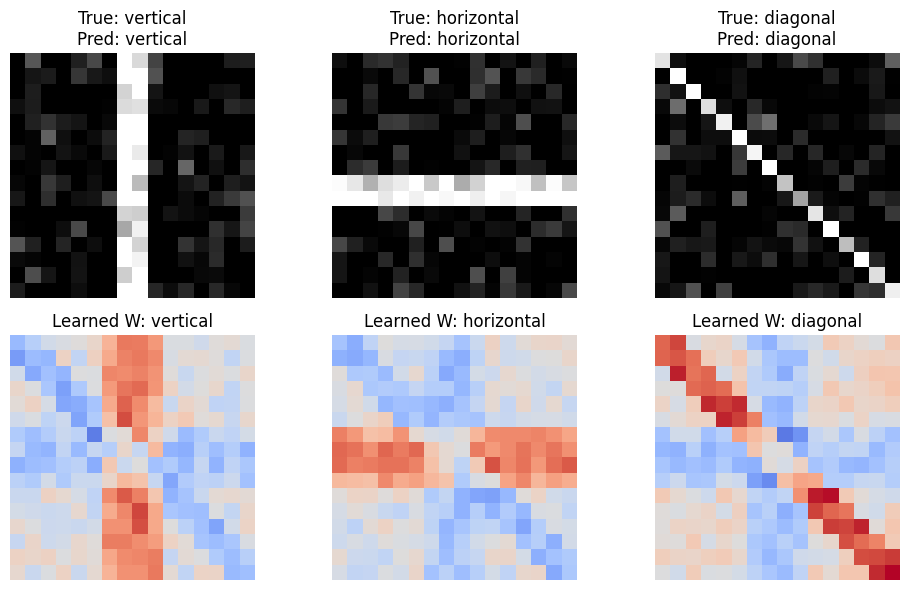

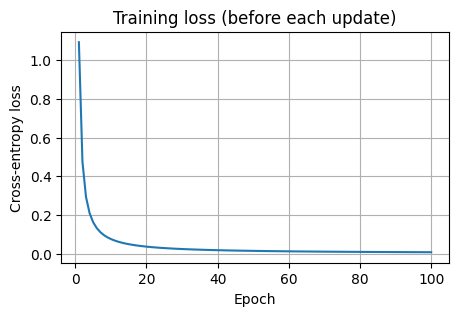

In [1]:
### CS231n_Lec02_review_Linear_Classifier

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

IMAGE_SIZE = 16
NUM_CLASSES = 3
CLASS_NAMES = ("vertical", "horizontal", "diagonal")


## Generate three types of line images and meaningful ground-truth labels
def make_dataset(num_samples):

    # images.shape = (N, C, H, W)
    images = torch.zeros(num_samples, 1, IMAGE_SIZE, IMAGE_SIZE)
    labels = torch.randint(0, NUM_CLASSES, (num_samples,))

    for i in range(num_samples):
        label = labels[i].item()
        shift = torch.randint(-1, 2, ()).item()

        if label == 0:
            # vertical line near the center with randomly shifted
            column = IMAGE_SIZE // 2 + shift
            images[i, 0, :, column - 1:column + 1] = 1.0

        elif label == 1:
            # horizontal line near the center with randomly shifted
            row = IMAGE_SIZE // 2 + shift
            images[i, 0, row - 1:row + 1, :] = 1.0

        else:
            # diagonal with slightly shifted
            for row in range(IMAGE_SIZE):
                column = row + shift

                if 0 <= column < IMAGE_SIZE:
                    images[i, 0, row, column] = 1.0

        # Add tiny pixel noises like signal noises
        images[i] += 0.15 * torch.randn_like(images[i])
        images[i].clamp_(0.0, 1.0)

    return images, labels


## Create the train and test datasets.
train_images, train_labels = make_dataset(600)
test_images, test_labels = make_dataset(150)

print("Original image shape:", train_images.shape)


## Flatten each image to a vector of length 256
train_x = train_images.flatten(start_dim=1)
test_x = test_images.flatten(start_dim=1)

print("Flattened input shape:", train_x.shape)


## Implement a simple linear classifier model
class LinearImageClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        # 16×16(IMAGE_SIZE) input features → 3 class scores
        self.linear = nn.Linear(
            IMAGE_SIZE * IMAGE_SIZE,
            NUM_CLASSES
        )

    def forward(self, x):
        scores = self.linear(x)
        return scores

model = LinearImageClassifier()

## Compute and initialize the starting scores without tracking gradients (saves
# memory)
with torch.no_grad():
    initial_scores = model(test_x[:4])

print("Initial score shape:", initial_scores.shape)
print("Initial scores:\n", initial_scores)
print("True labels:", test_labels[:4].tolist())


## Set the criterion(loss function) and optimizer(SGD)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.5)

loss_history = []


## Train for 100 epochs
for epoch in range(1, 101):
    scores = model(train_x)
    loss = criterion(scores, train_labels)

    optimizer.zero_grad() # Initialize gradients from the previous loop
    loss.backward() # Calculate the gradient of each parameter through backpropagation
    optimizer.step() # Update parameters (weights) using the calculated gradients.

    loss_history.append(loss.item()) # Loss before this epoch's update

    # Report loss and accuracy AFTER the update, every 20 epochs and at epoch 1
    if epoch == 1 or epoch % 20 == 0:
        with torch.no_grad():
            updated_scores = model(train_x)
            updated_loss = criterion(updated_scores, train_labels)
            predictions = updated_scores.argmax(dim=1)
            accuracy = (predictions == train_labels).float().mean()

        print(
            f"epoch={epoch:3d} | "
            f"loss={updated_loss.item():.4f} | "
            f"train accuracy={accuracy.item():.3f}"
        )


## Compute the test scores without tracking gradients (saves memory)
with torch.no_grad():
    test_scores = model(test_x)
    test_predictions = test_scores.argmax(dim=1)
    test_accuracy = (
        test_predictions == test_labels
    ).float().mean()

print("\nTest score shape:", test_scores.shape)
print(f"Test accuracy: {test_accuracy.item():.3f}")


## Weight shape of the linear layer:
# (Number of classes, Number of input features) = (3, 256)
weights = model.linear.weight.detach()
print("Weight matrix shape:", weights.shape)

weight_images = weights.reshape(
    NUM_CLASSES, IMAGE_SIZE, IMAGE_SIZE
)


## Visualize examples selected by true label, their predictions, and learned weights
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(10, 6))
weight_limit = max(weight_images.abs().max().item(), 1e-8)

for class_index in range(NUM_CLASSES):
    sample_indices = (
        test_labels == class_index
    ).nonzero(as_tuple=True)[0]
    if sample_indices.numel() > 0:
        sample_index = sample_indices[0].item()
        prediction = CLASS_NAMES[test_predictions[sample_index].item()]

        axes[0, class_index].imshow(
            test_images[sample_index, 0], cmap="gray", vmin=0, vmax=1
        )
        axes[0, class_index].set_title(
            f"True: {CLASS_NAMES[class_index]}\nPred: {prediction}"
        )
    else:
        axes[0, class_index].set_title(f"No samples: {CLASS_NAMES[class_index]}")

    axes[1, class_index].imshow(
        weight_images[class_index],
        cmap="coolwarm",
        vmin=-weight_limit,
        vmax=weight_limit
    )
    axes[1, class_index].set_title(
        f"Learned W: {CLASS_NAMES[class_index]}"
    )

    axes[0, class_index].axis("off")
    axes[1, class_index].axis("off")

plt.tight_layout()
plt.show()

plt.figure(figsize=(5, 3))
plt.plot(range(1, len(loss_history) + 1), loss_history)
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training loss (before each update)")
plt.grid(True)
plt.show()

Right shift: 4 pixels | input shape: (150, 256)
Overall accuracy: original=1.000, shifted=0.360
vertical: original=1.000, shifted=0.000
horizontal: original=1.000, shifted=1.000
diagonal: original=1.000, shifted=0.068


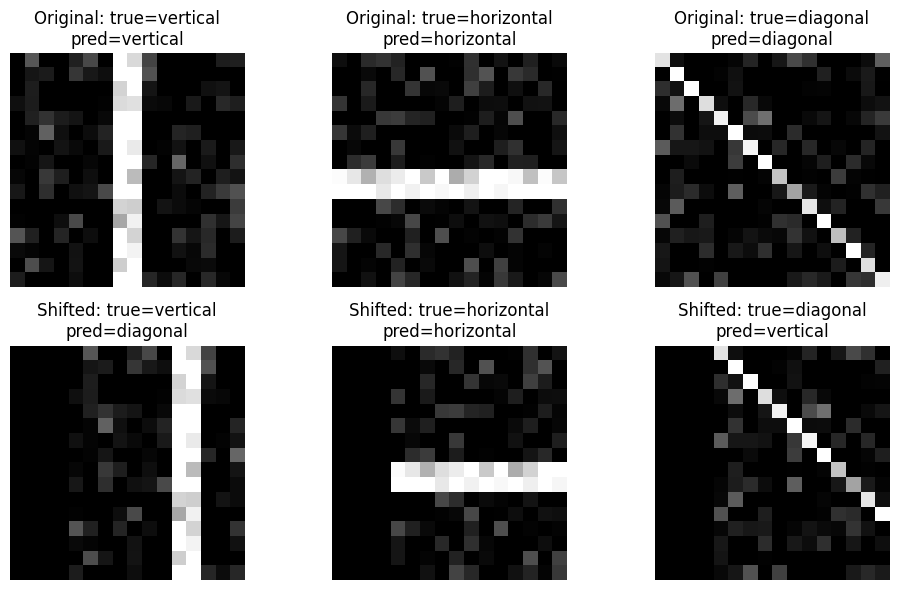

In [2]:
## Compare the same test samples before and after a horizontal shift.
SHIFT_PIXELS = 4
assert 0 <= SHIFT_PIXELS < IMAGE_SIZE # assure the limit of SHIFT_PIXELS

# Create a zero-tensor copying the shape and GPU location of test_images
shifted_images = torch.zeros_like(test_images)


## Shift image pixels to the right by SHIFT_PIXELS
# IF SHIFT_PIXELS == 0, the shift images are same as the original images
if SHIFT_PIXELS == 0:
    shifted_images.copy_(test_images)
else:
    shifted_images[:, :, :, SHIFT_PIXELS:] = test_images[:, :, :, :-SHIFT_PIXELS]
shifted_x = shifted_images.flatten(start_dim=1)


## Predict the labels with test & shifted dataset.
with torch.no_grad():
    original_predictions = model(test_x).argmax(dim=1)
    shifted_predictions = model(shifted_x).argmax(dim=1)


## Compare test accuracy on original & shifted Samples
print(f'Right shift: {SHIFT_PIXELS} pixels | input shape: {tuple(shifted_x.shape)}')
original_accuracy = (original_predictions == test_labels).float().mean().item()
shifted_accuracy = (shifted_predictions == test_labels).float().mean().item()
print(f'Overall accuracy: original={original_accuracy:.3f}, shifted={shifted_accuracy:.3f}')

# Create a subplot grid of 2 rows x NUM_CLASSES columns to visualize original and shifted images for each class
fig, axes = plt.subplots(2, NUM_CLASSES, figsize=(10, 6))

# Iterate through each class (vertical, horizontal, diagonal) to visualize results and compute class-specific accuracy
for class_index, class_name in enumerate(CLASS_NAMES):
    # Create a boolean mask to select only the test samples belonging to the current class
    mask = test_labels == class_index

    # Handle edge case where there are no test samples for the current class
    if not mask.any().item():
        print(f'{class_name}: no test samples')
        axes[0, class_index].axis('off')
        axes[1, class_index].axis('off')
        continue

    # Compute the classification accuracy for original and shifted images of this specific class
    original_class_accuracy = (original_predictions[mask] == test_labels[mask]).float().mean().item()
    shifted_class_accuracy = (shifted_predictions[mask] == test_labels[mask]).float().mean().item()
    print(f'{class_name}: original={original_class_accuracy:.3f}, shifted={shifted_class_accuracy:.3f}')

    # Retrieve the index of the first test sample belonging to this class for visualization
    sample_index = mask.nonzero(as_tuple=True)[0][0].item()

    # Plot the original image on the first row (0) and the shifted image on the second row (1)
    for row, images, predictions in [(0, test_images, original_predictions), (1, shifted_images, shifted_predictions)]:
        # Get the class name predicted by the model
        prediction = CLASS_NAMES[predictions[sample_index].item()]

        # Display the 2D image in grayscale with a fixed pixel value range of [0, 1]
        axes[row, class_index].imshow(images[sample_index, 0], cmap='gray', vmin=0, vmax=1)

        # Set the subplot title showing whether it's Original/Shifted, the true label, and the predicted label
        version = 'Original' if row == 0 else 'Shifted'
        axes[row, class_index].set_title(f'{version}: true={class_name}\npred={prediction}')

        # Hide axis ticks and labels to keep the visualization clean
        axes[row, class_index].axis('off')

# Adjust subplot spacing automatically and render the final plot
plt.tight_layout()
plt.show()